# SecondLook | 08 Fairness Audit

**Goal:** measure whether good borrowers are treated equally across **gender**, **age** and **thin file vs bureau history**, show how sure we are, and test one fix, so we can defend the model's limits on stage.

- **Who:** all 61,503 test applicants (never seen in training), with the shipped model's PD and the 0.17 cutoff.
- **Gender** is never a model input; it is kept only for this audit. **Age is a model input** (`AGE_YEARS`, and `EMPLOYED_TO_AGE`), as are family status, number of children and family size. That is the main question of this notebook.

| Metric | Question it answers |
|---|---|
| Approval rate | How often is the group approved? |
| Default rate | How risky is the group really? |
| **Approval rate of repayers** (equal opportunity) | Among people who *did* repay, how often were they approved? A fair model approves good borrowers at the same rate in every group |
| Decline rate of repayers | Good borrowers turned away (1 − the above) |
| Default rate of approved | Are the group's approvals "earned"? |
| Mean predicted PD vs actual default rate | Calibration: is the model's risk estimate right *for this group*? |
| Ratio to the best group | Approval rate ÷ best group's. The **four-fifths rule of thumb** flags a ratio under 0.8 |

## 1. Setup

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook.config import FIGURES_DIR, ID_COL, TARGET_COL
from secondlook import modeling as M
from secondlook import fairness as F
from secondlook.features import load_features

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

BUNDLE = ROOT / "app" / "demo_data"
meta = json.loads((BUNDLE / "model_meta.json").read_text())
CUTOFF = meta["cutoff"]
port = F.add_groups(pd.read_parquet(BUNDLE / "portfolio.parquet"))
print(f"{len(port):,} test applicants · cutoff {CUTOFF} · default rate {port[TARGET_COL].mean():.2%}")

61,503 test applicants · cutoff 0.17 · default rate 8.07%


## 2. Metrics per group

In [2]:
GROUPS = {"gender": "Gender", "age_band": "Age band", "credit_file": "Credit file"}
COLS = ["applicants", "approval_rate", "default_rate", "repayer_approval", "repayer_decline",
        "default_rate_approved", "mean_pd", "calibration_gap", "ratio_to_best", "below_four_fifths"]
tables = {g: F.group_metrics(port, g, cutoff=CUTOFF)[COLS] for g in GROUPS}
for g, label in GROUPS.items():
    print(label)
    display(tables[g].style.format({c: "{:.1%}" for c in COLS[1:7]} | {"calibration_gap": "{:+.1%}",
                                   "ratio_to_best": "{:.2f}", "applicants": "{:,}"}))

Gender


,applicants,approval_rate,default_rate,repayer_approval,repayer_decline,default_rate_approved,mean_pd,calibration_gap,ratio_to_best,below_four_fifths
gender,,,,,,,,,,
men,"20,940",84.4%,10.2%,88.1%,11.9%,6.3%,9.3%,-0.9%,0.94,False
women,"40,561",90.1%,7.0%,92.2%,7.8%,4.8%,7.2%,+0.2%,1.00,False


Age band


,applicants,approval_rate,default_rate,repayer_approval,repayer_decline,default_rate_approved,mean_pd,calibration_gap,ratio_to_best,below_four_fifths
age_band,,,,,,,,,,
20s,"8,905",79.2%,11.3%,83.1%,16.9%,6.9%,11.3%,-0.0%,0.82,False
30s,"16,487",84.2%,9.6%,87.6%,12.4%,5.9%,9.4%,-0.2%,0.87,False
40s,"15,303",89.3%,7.6%,91.8%,8.2%,5.0%,7.5%,-0.0%,0.93,False
50s,"13,617",93.3%,6.3%,94.9%,5.1%,4.8%,6.1%,-0.3%,0.97,False
60s,"7,191",96.4%,5.0%,97.2%,2.8%,4.2%,4.8%,-0.2%,1.00,False


Credit file


,applicants,approval_rate,default_rate,repayer_approval,repayer_decline,default_rate_approved,mean_pd,calibration_gap,ratio_to_best,below_four_fifths
credit_file,,,,,,,,,,
bureau history,"52,727",89.1%,7.7%,91.6%,8.4%,5.2%,7.6%,-0.1%,1.00,False
thin file,"8,776",82.7%,10.1%,86.2%,13.8%,6.3%,10.0%,-0.1%,0.93,False


**Interpretation:**
- **These reproduce the Phase 1 Model Card:** repayers are approved **88.1% (men) vs 92.2% (women)** and **83.1% (20s) vs 97.2% (60s)**.
- **No group falls under the four-fifths line.** The lowest ratio is people in their 20s at 0.82, close to the line.
- **The model is well calibrated in every group:** mean predicted PD is within half a point of the actual default rate everywhere. So the gaps are not the model *mis-estimating* a group's risk. Groups with more defaults (men, younger people, thin files) really do default more in this data, and a single cutoff then approves fewer of their good borrowers too.
- That is the tension: a calibrated model with one cutoff still gives **unequal opportunity** to good borrowers in higher-risk groups.

## 3. How sure are we? Bootstrap 95% intervals

We resample the 61,503 applicants 1,000 times and recompute each gap. If the 95% interval excludes zero, the gap is real, not noise from who happened to land in the test set.

In [3]:
PAIRS = [("gender", "women", "men"), ("age_band", "60s", "20s"), ("age_band", "40s", "20s"),
         ("credit_file", "bureau history", "thin file")]
gaps = pd.DataFrame([F.bootstrap_gap(port, g, a, b, cutoff=CUTOFF, metric=m)
                     for g, a, b in PAIRS for m in ("repayer_approval", "approval_rate")])
gaps["reading"] = [f"{r.a} {'+' if r.gap > 0 else ''}{r.gap * 100:.1f} pts vs {r.b} "
                   f"(95% CI {r.low * 100:.1f} to {r.high * 100:.1f}){'' if r.real else ', could be noise'}"
                   for r in gaps.itertuples()]
gaps[["group", "metric", "gap", "low", "high", "real", "reading"]].round(4)

,group,metric,gap,low,high,real,reading
0,gender,repayer_approval,0.0415,0.0363,0.0470,True,women +4.2 pts vs men (95% CI 3.6 to 4.7)
1,gender,approval_rate,0.0568,0.0511,0.0623,True,women +5.7 pts vs men (95% CI 5.1 to 6.2)
2,age_band,repayer_approval,0.1409,0.1324,0.1503,True,60s +14.1 pts vs 20s (95% CI 13.2 to 15.0)
3,age_band,approval_rate,0.1728,0.1637,0.1828,True,60s +17.3 pts vs 20s (95% CI 16.4 to 18.3)
4,age_band,repayer_approval,0.0865,0.0769,0.0954,True,40s +8.7 pts vs 20s (95% CI 7.7 to 9.5)
5,age_band,approval_rate,0.1013,0.0925,0.1111,True,40s +10.1 pts vs 20s (95% CI 9.3 to 11.1)
6,credit_file,repayer_approval,0.0534,0.0455,0.0609,True,bureau history +5.3 pts vs thin file (95% CI 4.6 to 6.1)
7,credit_file,approval_rate,0.0640,0.0557,0.0722,True,bureau history +6.4 pts vs thin file (95% CI 5.6 to 7.2)


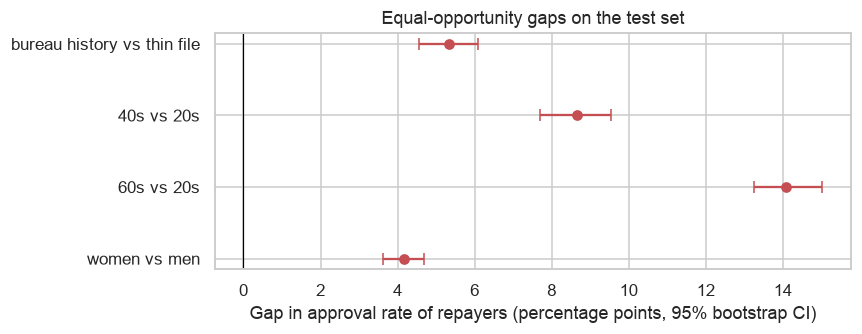

In [4]:
eo = gaps[gaps["metric"] == "repayer_approval"].copy()
eo["label"] = eo["a"] + " vs " + eo["b"]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(eo["gap"] * 100, eo["label"], xerr=[(eo["gap"] - eo["low"]) * 100, (eo["high"] - eo["gap"]) * 100],
            fmt="o", color="#C44E52", capsize=4)
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Gap in approval rate of repayers (percentage points, 95% bootstrap CI)", ylabel=None,
       title="Equal-opportunity gaps on the test set")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "28_fairness_gaps.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Fix experiment: retrain without the sensitive features

Same split, same parameters, same number of trees as the shipped model (`modeling.fit_lgbm`), with five features removed: `AGE_YEARS`, `EMPLOYED_TO_AGE`, `NAME_FAMILY_STATUS`, `CNT_CHILDREN`, `CNT_FAM_MEMBERS`. We first retrain **with** all features to check that retraining reproduces the shipped model, so any difference below comes from the removed features alone.

In [5]:
SENSITIVE_INPUTS = ["AGE_YEARS", "EMPLOYED_TO_AGE", "NAME_FAMILY_STATUS", "CNT_CHILDREN", "CNT_FAM_MEMBERS"]
df = load_features()
train, test = M.split(df)
assert (test[ID_COL].values == port[ID_COL].values).all()          # same test applicants, same order

feats, cats = meta["features"], meta["categorical"]
params = {k: v for k, v in M.LGBM_PARAMS.items() if k != "n_estimators"}
models = {}
for name, cols in [("shipped (retrained)", feats), ("without sensitive features", [f for f in feats if f not in SENSITIVE_INPUTS])]:
    cat_cols = [c for c in cats if c in cols]
    Xtr = M.prepare_X(train, cols, cat_cols, meta["categories"])
    Xte = M.prepare_X(test, cols, cat_cols, meta["categories"])
    m = M.fit_lgbm(Xtr, train[TARGET_COL], n_estimators=meta["n_trees"], params=params)
    models[name] = m.predict_proba(Xte)[:, 1]
    print(f"{name}: {len(cols)} features, test AUC {M.scores(test[TARGET_COL], models[name])['roc_auc']:.4f}")
print(f"Largest difference between the retrained and the shipped model's PD: {np.abs(models['shipped (retrained)'] - port['PD_LGBM']).max():.2e}")

shipped (retrained): 158 features, test AUC 0.7864


without sensitive features: 153 features, test AUC 0.7850
Largest difference between the retrained and the shipped model's PD: 1.11e-16


In [6]:
pa = M.ProfitAssumptions(**meta["profit_assumptions"])
rows = []
for name, p in [("shipped model", port["PD_LGBM"].to_numpy()), ("without sensitive features", models["without sensitive features"])]:
    d = port.assign(PD_X=p)
    curve = M.profit_curve(d[TARGET_COL], p, d["AMT_CREDIT"], pa)
    best = curve.loc[curve["profit"].idxmax()]
    row = {"model": name, "AUC": M.scores(d[TARGET_COL], p)["roc_auc"], "best cutoff": best["cutoff"],
           "profit at best cutoff (M)": best["profit"] / 1e6,
           "profit at 0.17 (M)": curve.loc[np.isclose(curve["cutoff"], CUTOFF), "profit"].iloc[0] / 1e6,
           "approval rate at 0.17": (p < CUTOFF).mean()}
    for g, a, b in PAIRS[:2] + PAIRS[3:]:
        r = F.bootstrap_gap(d, g, a, b, pd_col="PD_X", cutoff=CUTOFF, n_boot=1000)
        row[f"EO gap {a} vs {b}"] = f"{r['gap'] * 100:+.1f} ({r['low'] * 100:.1f} to {r['high'] * 100:.1f})"
    rows.append(row)
compare = pd.DataFrame(rows).set_index("model").T
compare

model,shipped model,without sensitive features
AUC,0.786419,0.78499
best cutoff,0.17,0.2
profit at best cutoff (M),3678.969019,3686.552847
profit at 0.17 (M),3678.969019,3675.789176
approval rate at 0.17,0.881908,0.881095
EO gap women vs men,+4.2 (3.6 to 4.7),+4.2 (3.6 to 4.7)
EO gap 60s vs 20s,+14.1 (13.2 to 15.0),+16.0 (15.1 to 17.0)
EO gap bureau history vs thin file,+5.3 (4.6 to 6.1),+4.7 (3.9 to 5.5)


,shipped,without sensitive,calibration gap without
age_band,,,
20s,83.1%,81.3%,0.5%
30s,87.6%,88.5%,-0.5%
40s,91.8%,92.0%,-0.2%
50s,94.9%,94.4%,-0.0%
60s,97.2%,97.3%,-0.2%


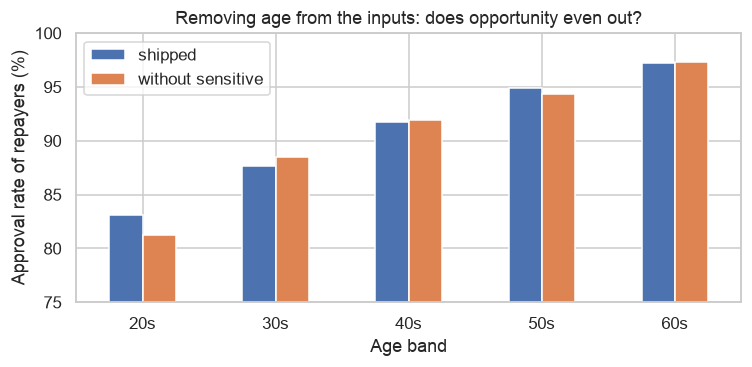

In [7]:
no_sens = F.add_groups(port.assign(PD_LGBM=models["without sensitive features"]))
age_compare = pd.DataFrame({
    "shipped": F.group_metrics(port, "age_band", cutoff=CUTOFF)["repayer_approval"],
    "without sensitive": F.group_metrics(no_sens, "age_band", cutoff=CUTOFF)["repayer_approval"],
    "calibration gap without": F.group_metrics(no_sens, "age_band", cutoff=CUTOFF)["calibration_gap"],
})
display(age_compare.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(7, 3.5))
age_compare[["shipped", "without sensitive"]].mul(100).plot.bar(ax=ax, rot=0, color=["#4C72B0", "#DD8452"])
ax.set(ylabel="Approval rate of repayers (%)", xlabel="Age band", ylim=(75, 100),
       title="Removing age from the inputs: does opportunity even out?")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "29_fairness_fix.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Decision

**Interpretation of the experiment:** retraining reproduces the shipped model exactly (largest PD difference 1e-16), so the comparison is fair. Without the five sensitive features:
- **AUC drops slightly** (0.7864 → 0.7850) and profit at the 0.17 cutoff falls by 3.2M (−0.1%).
- **The age gap gets worse, not better:** good borrowers in their 20s are approved **81.3%** instead of 83.1%, and the 60s vs 20s equal-opportunity gap widens from **14.1 to 16.0 points** (intervals do not overlap). The gender gap is unchanged (4.2 points) and the thin-file gap narrows a little (5.3 → 4.7).
- **Why?** Age is still visible through other features (years employed, length of credit history, number of past loans). Without the age column, the model reads youth from those proxies more crudely, and younger applicants come out *worse*. Removing a sensitive column is "fairness through unawareness", and here it does not work.

**Decision (Nov 27): we keep the shipped model with age as an input.** Removing age costs accuracy and widens the age gap it was meant to close. Instead, SecondLook handles fairness in the process: age, family status, children and family size are **never cited in a letter or suggested as a change** (notebook 05 and the letter checks), the 17–22% band goes to a **loan officer's second look**, and these gaps are monitored with this notebook. Because the model, app, letters and README already use this model, no numbers need to be rebuilt.

In [8]:
out = {
    "cutoff": CUTOFF,
    "groups": {g: tables[g].reset_index().rename(columns={g: "group"}).to_dict("records") for g in GROUPS},
    "gaps": gaps.drop(columns="reading").to_dict("records"),
    "experiment": compare.reset_index().rename(columns={"index": "metric"}).astype(str).to_dict("records"),
}
(BUNDLE / "fairness.json").write_text(json.dumps(out, indent=1, default=str))
print("Saved app/demo_data/fairness.json")

Saved app/demo_data/fairness.json


## Takeaways

1. **The Phase 1 Model Card numbers reproduce:** repayers are approved 88.1% (men) vs 92.2% (women), and 83.1% (20s) vs 97.2% (60s). Thin-file repayers: 86.2% vs 91.6% with a bureau record.
2. **Every gap is real.** With 1,000 bootstrap resamples, the equal-opportunity gaps are women +4.2 points vs men (95% CI 3.6 to 4.7), 60s +14.1 vs 20s (13.2 to 15.0) and bureau history +5.3 vs thin file (4.6 to 6.1). None of the intervals comes near zero.
3. **No group fails the four-fifths rule of thumb**; the lowest approval ratio is 0.82 (people in their 20s), close to the line.
4. **The model is calibrated in every group** (predicted vs actual default rate within half a point), so the gaps come from real differences in default rates meeting one cutoff, not from the model misjudging a group.
5. **Removing age and family features made the age gap worse** (14.1 → 16.0 points) and cost a little AUC (0.7864 → 0.7850). We keep the shipped model and rely on the process: no sensitive reasons in letters or paths, and a human second look for the borderline band.

**Limits:** this is one test set from one lender in an undisclosed country; group gaps must be re-measured on local data before any real use, and only gender and age could be audited (the data has no other protected traits).